# Transformer model-family comparison — T2 extension

**Purpose:** Compare Chained Ridge, LightGBM chained imputation, and optionally the experimental TabPFN extension with the same spatially held-out, originally missing transformer cells used by T2.

The original T2 and T3 results remain untouched. The saved Predictive MissForest score is loaded from T2, **not retrained**. Use the default full reference condition for final-report descriptive results.

**Caution:** TabPFN requires separately installed packages/model weights, its weight licence must be checked for your SAPN collaboration, and a reduced context size is not a strictly matched comparison.

In [1]:
from pathlib import Path
import subprocess
import sys
import pandas as pd
from IPython.display import display, Image

# Works from notebook folder or project root.
experiment = next((parent / 'experiment' / 'transformer'
                   for parent in [Path.cwd(), *Path.cwd().parents]
                   if (parent / 'experiment' / 'transformer' / 'scripts').is_dir()), None)
if experiment is None:
    experiment = next((parent for parent in [Path.cwd(), *Path.cwd().parents]
                       if (parent / 'scripts' / 'run_model_comparison.py').is_file()), None)
if experiment is None:
    raise FileNotFoundError('Cannot locate experiment/transformer directory')
print('Experiment:', experiment)
print('Python:', sys.executable)

Experiment: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer
Python: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/.pipeline/bin/python


## Choose execution mode

Set `RUN_NEW=True` to train and evaluate new candidates. For a quick smoke test use `QUICK=True`. Leave both False to load the verified anchor outputs already supplied (if included in your archive).

The default excludes TabPFN. When you have installed its extension, selected suitable hardware, and checked the licence, add `tabpfn_unsupervised` to the list.

In [2]:
RUN_NEW = True
QUICK = False
METHODS = ['median_mode', 'chained_ridge', 'lightgbm_chained']
CASES = '0.8:0.05'  # anchor: 20% missing, ±5% measurement noise

if RUN_NEW:
    command = [sys.executable, str(experiment / 'scripts' / 'run_model_comparison.py'),
               '--methods', ','.join(METHODS), '--cases', CASES]
    if QUICK:
        command.append('--quick')
    print('Command:', ' '.join(command))
    subprocess.run(command, check=True)
else:
    print('Using saved results only (no training).')

Command: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/.pipeline/bin/python /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer/scripts/run_model_comparison.py --methods median_mode,chained_ridge,lightgbm_chained --cases 0.8:0.05
Scenario completion=0.8, noise=0.05, len(train)=8000, len(test)=2000
 median_mode: fit=0.00s, transform=0.00s, skill=0.000
 chained_ridge: fit=0.25s, transform=0.05s, skill=0.699
 lightgbm_chained: fit=3.42s, transform=0.14s, skill=0.769
T2 baseline check mae: max absolute difference 0
T2 baseline check macro_f1: max absolute difference 0

               method       protocol  completion  noise  split_seed  mean_numeric_skill_ex_placebo  placebo_skill  model_id_macro_f1  fit_seconds  transform_seconds
        chained_ridge unseen_records         0.8   0.05         617                       0.699438      -0.002028           0.972716     0.254377           0.052243
     lightgbm_chained unseen_records         0.8   0.

In [3]:
# Latest full anchor run: choose a custom run directory here if desired.
OUTPUT_DIR = experiment / 'outputs' / 'model_comparison_anchor_20261112'
if not OUTPUT_DIR.exists():
    options = sorted((experiment / 'outputs').glob('model_comparison_full_*'), reverse=True)
    if not options:
        raise FileNotFoundError('No full model-comparison results found. Set RUN_NEW=True and QUICK=False.')
    OUTPUT_DIR = options[0]
print('Loading:', OUTPUT_DIR)
summary = pd.read_csv(OUTPUT_DIR / 'method_summary.csv')
display(summary.sort_values('mean_numeric_skill_ex_placebo', ascending=False))

Loading: /Users/zisanaalam/Desktop/GitHub/team19-asset-data/pipeline/experiment/transformer/outputs/model_comparison_full_20261113_061733


,method,protocol,completion,noise,split_seed,mean_numeric_skill_ex_placebo,placebo_skill,model_id_macro_f1,fit_seconds,transform_seconds
1,lightgbm_chained,unseen_records,0.8,0.05,617,0.769018,-0.018391,0.979885,3.418681,0.136725
3,predictive_missforest,unseen_records,0.8,0.05,617,0.709253,-0.013065,0.985399,NaN,NaN
0,chained_ridge,unseen_records,0.8,0.05,617,0.699438,-0.002028,0.972716,0.254377,0.052243
2,median_mode,unseen_records,0.8,0.05,617,0.000000,0.000000,0.112689,0.002021,0.001156


In [4]:
details = pd.read_csv(OUTPUT_DIR / 'per_target_metrics.csv')
numeric = details[details['variable_type'].eq('numeric') & details['variable'].ne('random_placebo')]
display(numeric.pivot(index='variable', columns='method', values='numeric_skill').round(3))
display(details[details['variable'].eq('model_id')][['method', 'accuracy', 'balanced_accuracy', 'macro_f1']])

method,chained_ridge,lightgbm_chained,median_mode,predictive_missforest
variable,,,,
altitude,0.792,0.761,0.0,0.676
install_date,0.941,0.957,0.0,0.913
leakage,0.176,0.209,0.0,0.168
life,0.542,0.854,0.0,0.780
measured_gas_a,0.880,0.881,0.0,0.898
measured_gas_b,0.864,0.868,0.0,0.869
measured_gas_c,0.871,0.874,0.0,0.864
measured_humid,0.600,0.727,0.0,0.635
measured_overgrowth,0.646,0.808,0.0,0.726


,method,accuracy,balanced_accuracy,macro_f1
14,median_mode,0.290954,0.250000,0.112689
29,chained_ridge,0.973105,0.968878,0.972716
44,lightgbm_chained,0.980440,0.977400,0.979885
59,predictive_missforest,0.985330,0.983790,0.985399


model_comparison_attribute_skill.png


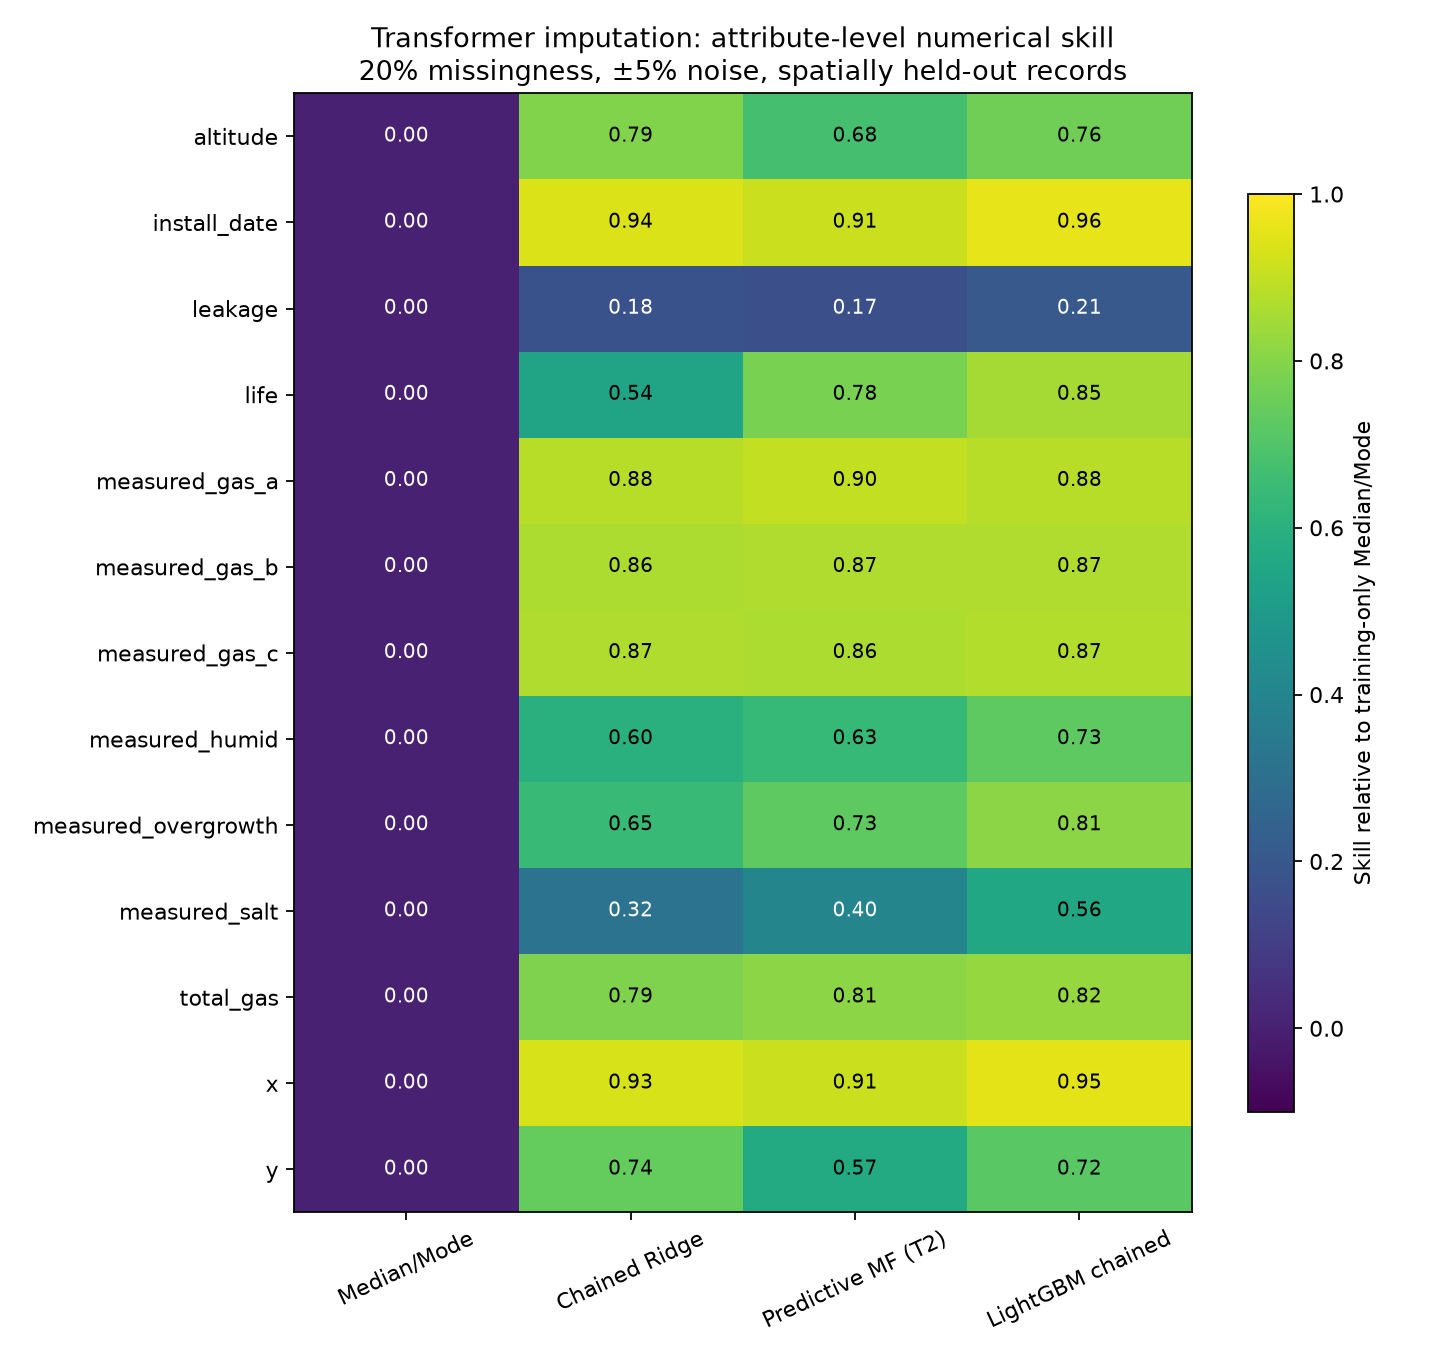

model_comparison_overview.png


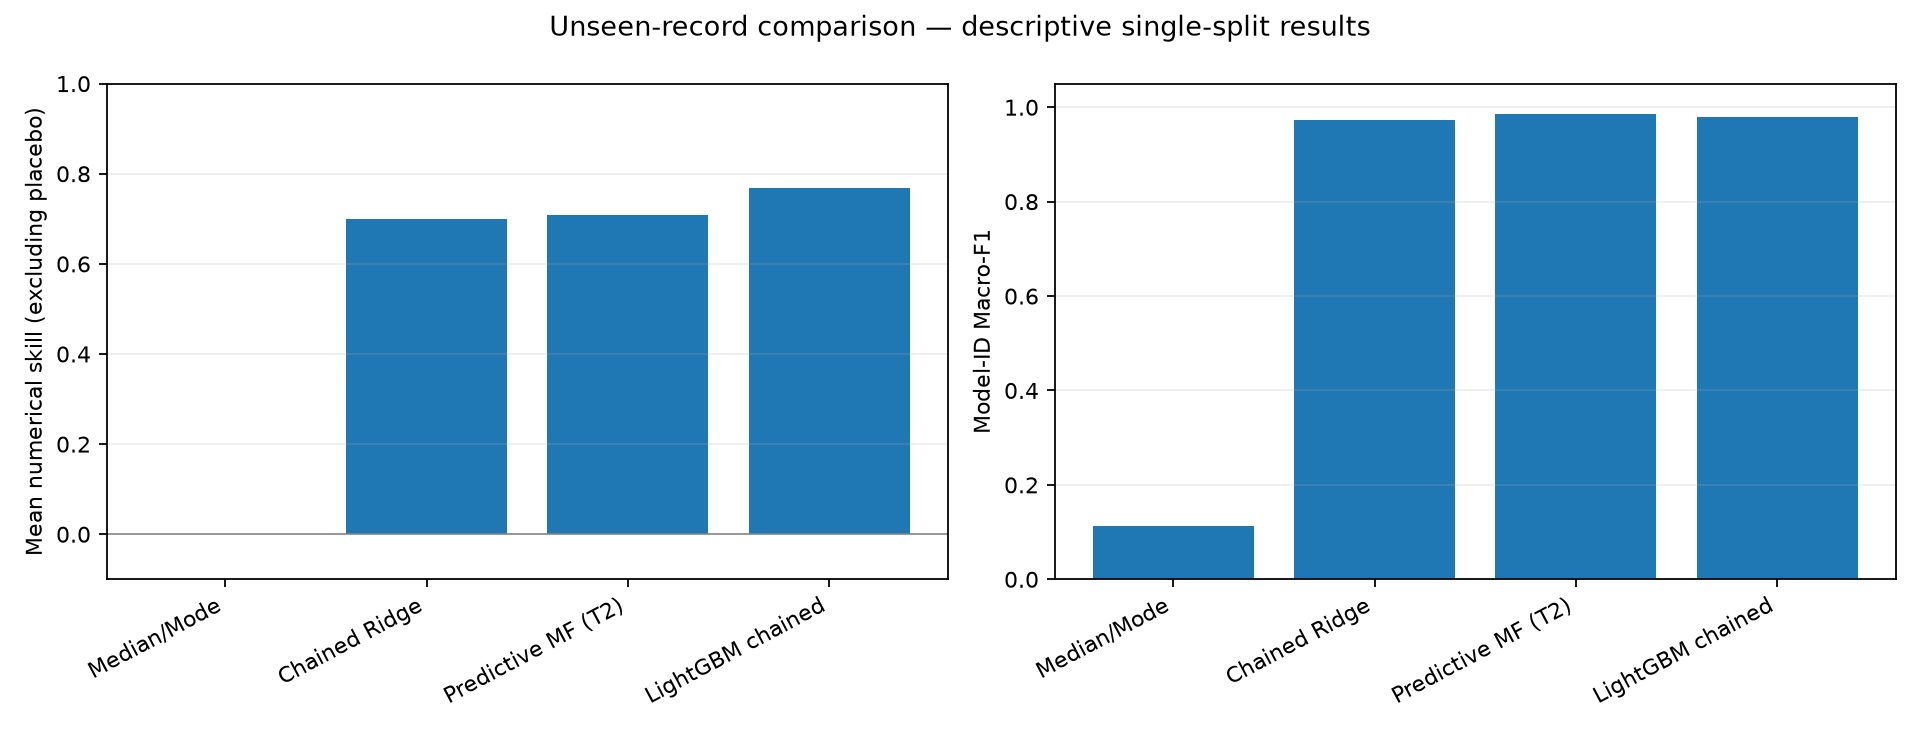

In [5]:
sys.path.insert(0, str(experiment / 'scripts'))
from plot_model_comparison import make_figures
for path in make_figures(OUTPUT_DIR):
    print(path.name)
    display(Image(filename=str(path)))

## Interpretation and reproducibility notes

- Results are descriptive for a **single synthetic population and split**. Do not state model equivalence, statistical significance or SAPN operational failure thresholds.
- Per-attribute scores matter more than the averaged numerical skill.
- High installation-date scores can exploit the synthetic coordinate-order shortcut.
- The TabPFN wrapper is an **optional experimental method**; no TabPFN result is included unless you execute it successfully. If it trains on a reduced context, disclose the sample-size mismatch.
- Current exports include individual masked-cell predictions for the new methods. The original Predictive MissForest T2 reference provides aggregate metrics only.
- Next: spatial-block paired bootstrap for new candidate pairs, independent synthetic repetitions, then grouped missingness and targeted corruption.